# RAG: Baseline vs Re-Ranking

**Document:** ICC Men's T20 World Cup 2026 Playing Conditions (106 pages, Feb 2026)

| | Pipeline 1 (baseline) | Pipeline 2 (re-ranking) |
|---|---|---|
| retrieve | bi-encoder, top 10 by cosine | same top 10 |
| re-rank | – | cross-encoder scores each (question, chunk) pair |
| answer | top 3 → LLM → **Answer 1** | new top 3 → LLM, same prompt → **Answer 2** |

Plus **No RAG** (question only) to show what the LLM knows without the document.

**Sections:** 1 Chunking · 2 Baseline retrieval · 3 Re-ranking · 4 LLM answers · 5 Failure analysis · 6 Latency

**Hardware:** 4× RTX 2080 Ti. GPU 0 runs the retrieval models; the LLM is served by vLLM across all 4 (`scripts/serve_llm.sh`).

## Setup

In [1]:
import os, re, random, hashlib, urllib.request
from pathlib import Path

ROOT = Path.cwd()
DATA, OUT = ROOT / "data", ROOT / "outputs"
DATA.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)
os.environ.setdefault("HF_HOME", str(ROOT / "models" / "hf"))  # keep model downloads in the project
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")

import pymupdf
import pandas as pd
from transformers import AutoTokenizer
from transformers.utils import logging as hf_logging
hf_logging.disable_progress_bar()

pd.set_option("display.max_colwidth", 140)
random.seed(0)

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.8,
              rc={"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "grid.color": "#e4e3df"})
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "gray": "#b8b7b1",          # categorical slots 1-3
     "good": "#0ca30c", "warn": "#fab219", "bad": "#d03b3b",                                  # status
     "z1": "#256abf", "z2": "#86b6ef"}                                                        # ordinal blues

## 1. Chunking

### 1.1 Load PDF
Not committed (ICC copyright), so it's downloaded from the ICC site if missing.

In [2]:
PDF_URL = "https://images.icc-cricket.com/image/upload/prd/yyt7m8uh9c1uehrbvuwb.pdf"
PDF_PATH = DATA / "icc_t20wc_2026_playing_conditions.pdf"
PDF_SHA256 = "0a5af6c6bd1677c835a4b7a0c81ebb68a1b0894c87ef0f158348dc84e58f323b"

if not PDF_PATH.exists():
    urllib.request.urlretrieve(PDF_URL, PDF_PATH)
sha = hashlib.sha256(PDF_PATH.read_bytes()).hexdigest()
assert sha == PDF_SHA256, f"PDF differs from the version used in this study: {sha}"

doc = pymupdf.open(PDF_PATH)
print(f"{PDF_PATH.name}: {doc.page_count} pages, {PDF_PATH.stat().st_size / 1e6:.1f} MB, sha256 OK")

icc_t20wc_2026_playing_conditions.pdf: 106 pages, 0.8 MB, sha256 OK


### 1.2 Raw text
Each page starts with a page number and a running header. Clause numbers are followed by a tab (`9.1\t`), and section titles are in caps.

In [3]:
print(repr(doc[15].get_text()[:700]))

"16\nPlaying Conditions  |  ICC Men's T20 World Cup 2026\n9\t\nPREPARATION AND MAINTENANCE OF \nTHE PLAYING AREA\n9.1\t\nRolling\nThe pitch shall not be rolled during the match except as permitted in clauses 9.1.1 and\xa09.1.2.\n9.1.1\t\nFrequency and duration of rolling During the match the pitch may be rolled at the \nrequest of the captain of the side batting second, for a period of not more than \n7\xa0minutes, before the start of the second innings.\n9.1.2\t\nRolling after a delayed start In addition to the rolling permitted above, if, after the toss \nand before the first innings of the match, the start is delayed, the captain of the batting \nside may request that the pitch be rolled for not more than 7 minute"


### 1.3 Clean
- Skip the cover (p.1), the contents pages (p.3, p.72) and Appendix E's blank calculation forms (p.98–99).
- Drop page numbers, headers and diagram labels. Labels are set in 7.9–9.2 pt and body text in 10 pt, so anything under 9.5 pt goes.

In [4]:
SKIP_PAGES = {1, 3, 72, 98, 99}   # cover, contents, appendix contents, Appendix E forms
HEADER_RE = re.compile(r"^\s*(\d{1,3}\s+)?(ICC Men's T20 World Cup 2026\s*\|\s*Playing Conditions"
                       r"|Playing Conditions\s*\|\s*ICC Men's T20 World Cup 2026)\s*$")

def small_text(page, max_size=9.5):
    # lines set in a small font: diagram labels, header, page number
    return {"".join(s["text"] for s in l["spans"]).strip()
            for b in page.get_text("dict")["blocks"] for l in b.get("lines", [])
            if l["spans"] and max(s["size"] for s in l["spans"]) < max_size}

def extract_lines(doc):
    lines = []                                   # (page_number, line)
    for pno, page in enumerate(doc, start=1):
        if pno in SKIP_PAGES:
            continue
        raw = page.get_text().replace("\xa0", " ").replace("\x07", "")
        small = small_text(page)
        for i, line in enumerate(raw.splitlines()):
            if i == 0 and line.strip() == str(pno):          # page number
                continue
            if HEADER_RE.match(line) or not line.strip() or re.search(r"_{3,}", line) or line.strip() in small:
                continue
            lines.append((pno, line.rstrip(" ")))    # keep TABs: they mark clause numbers
    return lines

lines = extract_lines(doc)
print(f"{len(lines)} lines kept from {doc.page_count - len(SKIP_PAGES)} pages")

5040 lines kept from 101 pages


### 1.4 Parse clauses
Walk through the lines, keeping track of the current appendix and section. Every clause number starts a new unit.

A clause title on its own line gets a colon, so it doesn't run into the rule: `9.1 Rolling: The pitch…`.

In [5]:
CLAUSE_RE = re.compile(r"^(\d{1,2}(?:\.\d{1,2})+|\d{1,2}\.)(?:\t\s*(.*)|\s*)$")
SECTION_RE = re.compile(r"^(\d{1,2})(?:\t\s*(.*)|\s*)$")
APPENDIX_RE = re.compile(r"^APPENDIX ([A-J]):\s*(.*)$")

def is_caps(line):
    letters = [c for c in line if c.isalpha()]
    return len(letters) >= 3 and all(c.isupper() for c in letters)

def read_caps_title(lines, j, first, stop_re):
    title = [first]
    while (j < len(lines) and is_caps(lines[j][1]) and not stop_re.match(lines[j][1])
           and not APPENDIX_RE.match(lines[j][1].strip())):
        title.append(lines[j][1].strip()); j += 1
    return " ".join(t for t in title if t), j

def parse_units(lines):
    units, appendix, section, cur = [], None, ("0", "PREAMBLE"), None
    def new(clause, pno, first=""):
        return {"appendix": appendix, "section": section, "clause": clause, "page": pno,
                "lines": [first] if first.strip() else [], "title_line": not first.strip()}
    i = 0
    while i < len(lines):
        pno, line = lines[i]
        nxt = lines[i + 1][1] if i + 1 < len(lines) else ""
        m_app, m_sec, m_cl = APPENDIX_RE.match(line.strip()), SECTION_RE.match(line), CLAUSE_RE.match(line)
        if m_app:
            units.append(cur)
            title, i = read_caps_title(lines, i + 1, m_app.group(2).strip(), SECTION_RE)
            appendix = (m_app.group(1), title)
            section = appendix
            cur = new(None, pno)
        elif m_sec and not m_cl and (is_caps(m_sec.group(2) or "") or (not (m_sec.group(2) or "").strip() and is_caps(nxt))):
            units.append(cur)
            title, i = read_caps_title(lines, i + 1, (m_sec.group(2) or "").strip(), CLAUSE_RE)
            section = (m_sec.group(1), title)
            cur = new(None, pno)
        elif m_cl and section[0].isdigit() and section[0] != "0" and "." in m_cl.group(1).rstrip(".") \
                and not m_cl.group(1).startswith(section[0] + "."):
            cur["lines"].append(line)                 # a number inside a table (e.g. "4.5" in 28.7), not a clause
            i += 1
        elif m_cl:
            units.append(cur)
            cur = new(m_cl.group(1).rstrip("."), pno, m_cl.group(2) or "")
            i += 1
        else:
            cur = cur or new(None, pno)               # preamble before the first section
            cur["lines"].append(line)
            i += 1
    units.append(cur)
    return [u for u in units if u and u["lines"]]

def join_lines(ls):
    t = "\n".join(l.strip() for l in ls if l.strip())
    t = re.sub(r"-\n(?=[a-z])", "-", t)              # "wicket-\nkeeper" -> "wicket-keeper"
    return re.sub(r"\s+", " ", t.replace("\t", " ").replace("\n", " ")).strip()

def clause_text(u):
    ls = [l for l in u["lines"] if l.strip()]
    if not u["clause"]:
        return join_lines(ls)
    first = ls[0].strip()
    # title on its own line: short, no end punctuation, next line starts a sentence
    if (u["title_line"] and len(ls) > 1 and len(first.split()) <= 8 and not re.search(r"[.;:,]$", first)
            and re.match(r"[A-Z0-9(–‘“\"]", ls[1].strip())):
        return f"{u['clause']} {first}: {join_lines(ls[1:])}"
    return f"{u['clause']} {join_lines(ls)}"

units = parse_units(lines)
for u in units:
    u["text"] = clause_text(u)
print(f"{len(units)} clause units")
pd.DataFrame([{"clause": u["clause"], "section": " ".join(u["section"]), "page": u["page"], "text": u["text"][:100]}
              for u in units[60:66]])

1200 clause units


,clause,section,page,text
0,2.7.1,2 THE UMPIRES,7,"2.7.1 It is solely for the umpires together to decide whether either conditions of ground, weather o"
1,2.7.2,2 THE UMPIRES,7,2.7.2 Conditions shall be regarded as dangerous if there is actual and foreseeable risk to the safet
2,2.7.3,2 THE UMPIRES,7,"2.7.3 Conditions shall be regarded as unreasonable if, although posing no risk to safety, it would n"
3,2.7.4,2 THE UMPIRES,7,2.7.4 If the umpires consider the ground is so wet or slippery as to deprive the bowler of a reasona
4,2.8,2 THE UMPIRES,7,2.8 Suspension of play in dangerous or unreasonable circumstances
5,2.8.1,2 THE UMPIRES,7,2.8.1 All references to ground include the pitch. See clause 6.1 (Area of pitch).


### 1.5 Chunk
- Merge consecutive clauses from the same section, up to ~180 tokens (MiniLM's limit is 256).
- Split clauses over 220 tokens by sentence, with 1 sentence of overlap. Later pieces start with `<clause> (cont.)`.
- Never leave a heading alone at the end of a chunk.

Chunks are kept small on purpose: with big chunks the answer is almost always in the top 3 already, and re-ranking has nothing to fix.

In [6]:
TARGET, MAX = 180, 220
tok = AutoTokenizer.from_pretrained("sentence-transformers/all-MiniLM-L6-v2")
ntok = lambda s: len(tok.tokenize(s))
for u in units:
    u["ntok"] = ntok(u["text"])

def split_sentences(text):
    sents = []
    for s in re.split(r"(?<=[.;:])\s+(?=[A-Z0-9(])", text):
        words = s.split()
        while ntok(" ".join(words)) > TARGET:    # very long sentence
            k = len(words) // 2
            while ntok(" ".join(words[:k])) > TARGET: k //= 2
            while k < len(words) and ntok(" ".join(words[:k + 10])) <= TARGET: k += 10
            sents.append(" ".join(words[:k])); words = words[k:]
        sents.append(" ".join(words))
    return sents

def split_long(u):
    out, win = [], []
    for s in split_sentences(u["text"]):
        if win and ntok(" ".join(win + [s])) > TARGET:
            out.append(" ".join(win))
            win = [win[-1]] if ntok(win[-1]) < TARGET // 3 else []
        win.append(s)
    out.append(" ".join(win))
    if u["clause"]:
        out = out[:1] + [f"{u['clause']} (cont.) {t}" for t in out[1:]]
    return [dict(u, text=t, ntok=ntok(t)) for t in out]

def pack(units):
    pieces = [p for u in units for p in (split_long(u) if u["ntok"] > MAX else [u])]
    chunks, buf = [], []
    def emit():
        clauses = [b["clause"] for b in buf if b["clause"]]
        chunks.append({"appendix": buf[0]["appendix"], "section": buf[0]["section"], "page": buf[0]["page"],
                       "clauses": (f"{clauses[0]}–{clauses[-1]}" if len(set(clauses)) > 1 else (clauses[0] if clauses else "")),
                       "text": " ".join(b["text"] for b in buf)})
    for p in pieces:
        same = buf and (p["appendix"], p["section"]) == (buf[0]["appendix"], buf[0]["section"])
        size = sum(b["ntok"] for b in buf)
        if buf and not (same and size < 15) and (not same or size + p["ntok"] > TARGET):
            carry = [buf.pop()] if same and len(buf) > 1 and buf[-1]["ntok"] < 15 else []   # bare heading
            emit(); buf = carry
        buf.append(p)
    emit()
    return chunks

chunks = pack(units)
print(f"{len(units)} clause units -> {len(chunks)} chunks")

1200 clause units -> 440 chunks


### 1.6 Two versions
`text` (A) and `text_titled` (B = `[section] ` + text). Same IDs in both.

In [7]:
SMALL = {"and", "of", "the", "for", "to", "on", "in", "a", "an", "or", "by"}
def nice(s):
    return " ".join(w if w.startswith("(") and w.strip("()").isupper() and len(w.strip("()")) <= 4
                    else w.lower() if k and w.lower() in SMALL else w.capitalize()
                    for k, w in enumerate(s.split()))

for k, c in enumerate(chunks):
    c["id"] = f"c{k:03d}"
    sec_num, sec_title = c["section"]
    path = f"Appendix {c['appendix'][0]}: {nice(c['appendix'][1])}" if c["appendix"] else ""
    if not c["appendix"] or sec_title != c["appendix"][1]:
        path = (path + " > " if path else "") + (nice(sec_title) if sec_num == "0" else f"{sec_num} {nice(sec_title)}")
    c["section_path"] = path
    c["text_titled"] = f"[{path}] {c['text']}"
    c["ntok"], c["ntok_titled"] = ntok(c["text"]), ntok(c["text_titled"])

df = pd.DataFrame(chunks)[["id", "section_path", "clauses", "page", "ntok", "ntok_titled", "text", "text_titled"]]
df.head(3)

,id,section_path,clauses,page,ntok,ntok_titled,text,text_titled
0,c000,Preamble,,2,165,170,PREAMBLE – THE SPIRIT OF CRICKET Cricket owes much of its appeal and enjoyment to the fact that it should be played not only according t...,[Preamble] PREAMBLE – THE SPIRIT OF CRICKET Cricket owes much of its appeal and enjoyment to the fact that it should be played not only ...
1,c001,Preamble,,2,81,86,"Congratulate the opposition on their successes, and enjoy those of your own team. Thank the officials and your opposition at the end of ...","[Preamble] Congratulate the opposition on their successes, and enjoy those of your own team. Thank the officials and your opposition at ..."
2,c002,1 The Players,1.1–1.2.1,4,137,142,"1.1 Number of players: A match is played between two sides, each of eleven players, one of whom shall be captain. 1.2 Nomination and rep...","[1 The Players] 1.1 Number of players: A match is played between two sides, each of eleven players, one of whom shall be captain. 1.2 No..."


### 1.7 Save

In [8]:
CHUNKS_PATH = DATA / "chunks.jsonl"
df.to_json(CHUNKS_PATH, orient="records", lines=True, force_ascii=False)
print(f"saved {len(df)} chunks -> {CHUNKS_PATH.relative_to(ROOT)}")

saved 440 chunks -> data/chunks.jsonl


### 1.8 Sanity checks

In [9]:
print(df[["ntok", "ntok_titled"]].describe().round(1).T[["count", "min", "25%", "50%", "75%", "max"]])
print(f"\nchunks over 256 tokens: plain {(df.ntok > 256).sum()}, titled {(df.ntok_titled > 256).sum()}")
print(f"main-body chunks: {(~df.section_path.str.startswith('Appendix')).sum()}, appendix chunks: {df.section_path.str.startswith('Appendix').sum()}")

             count   min    25%    50%    75%    max
ntok         440.0   4.0  115.0  148.0  168.0  215.0
ntok_titled  440.0  11.0  122.8  155.0  175.0  223.0

chunks over 256 tokens: plain 0, titled 0
main-body chunks: 324, appendix chunks: 116


In [10]:
# chunks per part
part = df.section_path.where(df.section_path.str.startswith("Appendix"), "Main body (sections 1-42)").str.split(" > ").str[0]
part.value_counts().sort_index().to_frame("chunks")

,chunks
section_path,
Appendix A: Definitions,28
Appendix B: Equipment,12
Appendix C: The Venue,3
Appendix D: Decision Review System (DRS),55
Appendix F: Super Over Procedure,9
Appendix G: Application of the Reserve Day for the Semi-finals and Final,4
Appendix H: Use of Electronic Communications Equipment,1
Appendix I: On-field Injury Assessments and Treatment,1
Appendix J: Summary of Changes to Playing Conditions for Warm-up Matches,3


In [11]:
# a few random chunks
for _, r in df.sample(3, random_state=1).iterrows():
    print(f"{r.id} | {r.section_path} | clauses {r.clauses} | p.{r.page} | {r.ntok} tokens\n{r.text}\n")

c283 | 41 Unfair Play | clauses 41.5.10–41.6.1 | p.62 | 141 tokens
41.5.10 The umpires may then report the matter to the ICC Match Referee who shall take such action as is considered appropriate against the fielder concerned. 41.6 Bowling of dangerous and unfair short pitched deliveries 41.6.1 Notwithstanding clause 41.6.2, the bowling of short pitched deliveries is dangerous if the bowler’s end umpire considers that, taking into consideration the skill of the striker, by their speed, length, height and direction they are likely to inflict physical injury on him. The fact that the striker is wearing protective equipment shall be disregarded. In the first instance the umpire decides that the bowling of short pitched deliveries has become dangerous under clause 41.6.1

c369 | Appendix D: Decision Review System (DRS) > 1 General | clauses 1.1.5 | p.88 | 158 tokens
1.1.5 The table below summarises the minimum requirements for DRS to be used, and the regulations around the appointment of th

Some chunks to keep in mind for later:
- 9.1: the rolling rule stays together with its exceptions
- Follow-on: the whole chunk is "Shall not apply.", so it can only be found in version B
- Main rules say 11 players, warm-ups (App. J) say max 15 → keyword trap

In [12]:
show = lambda mask: df[mask][["id", "section_path", "clauses", "page", "text"]]
pd.concat([
    show(df.text.str.contains("shall not be rolled")),
    show(df.text.str.fullmatch("Shall not apply.")),
    show(df.text.str.startswith("1.1 Number of players") | df.text.str.contains("Each side shall consist of a maximum 15 players")),
])

,id,section_path,clauses,page,text
54,c054,9 Preparation and Maintenance of the Playing Area,9.1–9.1.2,16,9.1 Rolling: The pitch shall not be rolled during the match except as permitted in clauses 9.1.1 and 9.1.2. 9.1.1 Frequency and duration...
92,c092,14 The Follow-on,,24,Shall not apply.
93,c093,15 Declaration and Forfeiture,,24,Shall not apply.
2,c002,1 The Players,1.1–1.2.1,4,"1.1 Number of players: A match is played between two sides, each of eleven players, one of whom shall be captain. 1.2 Nomination and rep..."
437,c437,Appendix J: Summary of Changes to Playing Conditions for Warm-up Matches,1.1,105,NOTE: ICC Men’s T20 World Cup 2026 warm-up matches will not be official Twenty 20 Internationals. ICC Match Referees will not be on duty...


In [13]:
r = df[df.section_path.str.contains("Follow-on")].iloc[0]
print("A:", r.text)
print("B:", r.text_titled)

A: Shall not apply.
B: [14 The Follow-on] Shall not apply.


## 2. Baseline retrieval (Pipeline 1)
A bi-encoder turns the question and each chunk into vectors **separately**; retrieval = top 10 chunks by cosine similarity.

In [14]:
import time, json
import numpy as np
import torch, faiss
from concurrent.futures import ThreadPoolExecutor, as_completed
from sentence_transformers import SentenceTransformer, CrossEncoder

chunks = pd.read_json(DATA / "chunks.jsonl", lines=True)
by_id = chunks.set_index("id")
CHUNK_IDS = chunks.id.to_numpy()
NGPU = torch.cuda.device_count()
gpu = lambda i: f"cuda:{i % NGPU}" if NGPU else "cpu"      # spread small models over the GPUs vLLM shares
DEVICE = gpu(0)
print(len(chunks), "chunks |", NGPU, "GPUs")

440 chunks | 4 GPUs


### 2.1 Bi-encoders
| model | dims | query input |
|---|---|---|
| `all-MiniLM-L6-v2` | 384 | question as is |
| `bge-small-en-v1.5` | 384 | `"Represent this sentence for searching relevant passages: " + question` |

Chunks go in as text: version **A** = plain, **B** = `[section path] ` + text.

In [15]:
BI_ENCODERS = {"minilm": ("sentence-transformers/all-MiniLM-L6-v2", ""),
               "bge": ("BAAI/bge-small-en-v1.5", "Represent this sentence for searching relevant passages: ")}
VERSIONS = {"A": "text", "B": "text_titled"}
SETUPS = [(m, v) for m in BI_ENCODERS for v in VERSIONS]
encoders = {m: SentenceTransformer(mid, device=DEVICE) for m, (mid, _) in BI_ENCODERS.items()}

# what goes into the model: one string in, one 384-d unit vector out
ex = chunks[chunks.text.str.startswith("9.1 Rolling")].iloc[0]
for label, s in [("chunk A", ex.text), ("chunk B", ex.text_titled),
                 ("query (bge)", BI_ENCODERS["bge"][1] + "How long can the pitch be rolled?")]:
    print(f"{label:12} {s[:110]}…")
print("output:", encoders["minilm"].encode([ex.text], normalize_embeddings=True).shape)

chunk A      9.1 Rolling: The pitch shall not be rolled during the match except as permitted in clauses 9.1.1 and 9.1.2. 9.…
chunk B      [9 Preparation and Maintenance of the Playing Area] 9.1 Rolling: The pitch shall not be rolled during the matc…
query (bge)  Represent this sentence for searching relevant passages: How long can the pitch be rolled?…
output: (1, 384)


### 2.2 Indexes
Normalised embeddings, so inner product = cosine. `IndexFlatIP` = exact search. 2 models × 2 versions = 4 indexes.

In [16]:
indexes = {}
for m, v in SETUPS:
    t0 = time.perf_counter()
    emb = encoders[m].encode(chunks[VERSIONS[v]].tolist(), batch_size=128, normalize_embeddings=True, convert_to_numpy=True)
    indexes[(m, v)] = faiss.IndexFlatIP(emb.shape[1])
    indexes[(m, v)].add(emb)
    print(f"{m}-{v}: {emb.shape} in {time.perf_counter() - t0:.2f}s")

minilm-A: (440, 384) in 0.41s


minilm-B: (440, 384) in 0.33s


bge-A: (440, 384) in 0.56s


bge-B: (440, 384) in 0.55s


### 2.3 Retrieval
`search` handles a whole batch of questions in one encode + one FAISS call. `retrieve` is the single-question version used for examples and latency.

In [17]:
def search(questions, model, version, k=10):
    prefix = BI_ENCODERS[model][1]
    q = encoders[model].encode([prefix + x for x in questions], batch_size=128, normalize_embeddings=True, convert_to_numpy=True)
    return indexes[(model, version)].search(q, k)            # (scores, row indices), each (n_questions, k)

def retrieve(question, model="minilm", version="A", k=10):
    scores, idx = search([question], model, version, k)
    hits = chunks.iloc[idx[0]][["id", "section_path", "clauses", "text"]].reset_index(drop=True)
    hits.insert(0, "rank", range(1, k + 1))
    hits.insert(2, "cosine", scores[0].round(3))
    return hits

### 2.4 Question set
40 questions in `eval/questions.csv`, 4 tiers of 10, each harder than the last:
1. **direct**: the rulebook's own wording
2. **paraphrase**: everyday fan wording
3. **exception / negation**: hinges on an "except / unless / shall not"
4. **keyword trap / cross-ref / multi-chunk**: warm-up vs main rules, Super Over appendix, answers split over chunks

Gold chunks are stored as anchor phrases (a quote from the rule, or `§section`), so labels survive re-chunking. All 40 were checked by independent reviewers against the rule text.

In [18]:
qs = pd.read_csv(ROOT / "eval" / "questions.csv")
QUESTION = qs.set_index("qid").question

def resolve(anchors):
    ids = []
    for a in anchors.split(" || "):
        m = chunks.section_path == a[1:] if a.startswith("§") else chunks.text.str.contains(a, regex=False)
        assert m.any(), f"anchor not found: {a}"
        ids += chunks[m].id.tolist()
    return ids

qs["gold"] = qs.gold_anchors.map(resolve)
GOLD_ROWS = [np.flatnonzero(np.isin(CHUNK_IDS, g)) for g in qs.gold]   # gold as chunk row numbers
qs[["qid", "tier", "type", "question", "gold"]].groupby("tier").head(1)

,qid,tier,type,question,gold
0,q01,1,direct,How many players are there on each side in a World Cup match?,[c002]
10,q11,2,paraphrase,Can the groundsman flatten the wicket at the innings break?,[c054]
20,q21,3,exception,"If the bowler oversteps the line and the batter skies it straight to a fielder, is he out?",[c174]
30,q31,4,keyword-trap,"In the practice games before the tournament, can all 15 nominated players bat?",[c438]


### 2.5 Baseline ranks
Rank of the best gold chunk among all chunks, per question and setup:
**≤ 3** the LLM sees it · **4–10** missed, but re-ranking can rescue it · **> 10** lost (re-ranking only sees the top 10).

In [19]:
def gold_rank_all(model, version):
    _, idx = search(qs.question.tolist(), model, version, k=len(chunks))
    pos = np.argsort(idx, axis=1)                              # pos[q, row] = 0-based rank of chunk row for question q
    return np.array([pos[i, g].min() + 1 for i, g in enumerate(GOLD_ROWS)])

ranks = qs[["qid", "tier", "type"]].copy()
for m, v in SETUPS:
    ranks[f"{m}-{v}"] = gold_rank_all(m, v)

ZONES = ["top 3", "4-10", ">10"]
zone = lambda r: ZONES[0] if r <= 3 else ZONES[1] if r <= 10 else ZONES[2]
zones = pd.concat({s: ranks.groupby("tier")[s].apply(lambda x: x.map(zone).value_counts()).unstack(fill_value=0).reindex(columns=ZONES, fill_value=0)
                   for s in ranks.columns[3:]}, axis=1)
zones

minilm-A          minilm-B          bge-A          bge-B         
        top 3 4-10 >10    top 3 4-10 >10 top 3 4-10 >10 top 3 4-10 >10
tier                                                                  
1          10    0   0       10    0   0    10    0   0    10    0   0
2           8    0   2        7    1   2     8    0   2     8    0   2
3           4    4   2        3    5   2     6    2   2     7    1   2
4           4    2   4        5    1   4     4    5   1     5    4   1

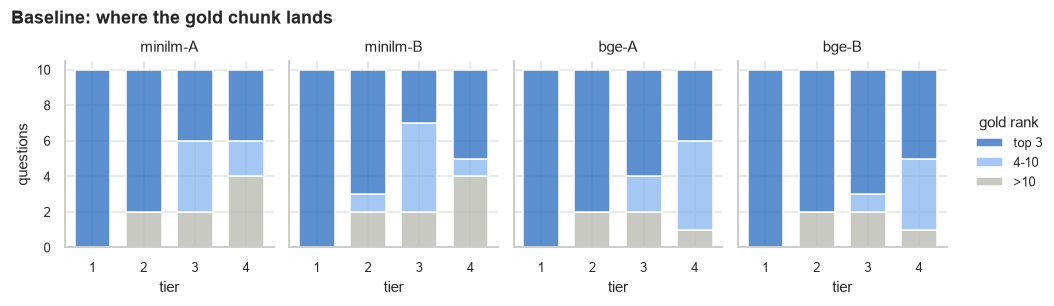

In [20]:
zl = ranks.melt(id_vars=["qid", "tier"], value_vars=list(ranks.columns[3:]), var_name="setup", value_name="rank")
zl["gold rank"] = zl["rank"].map(zone)
g = sns.displot(zl, x="tier", hue="gold rank", col="setup", multiple="stack", discrete=True, shrink=0.7,
                hue_order=ZONES, palette=[C["z1"], C["z2"], C["gray"]], height=2.6, aspect=0.85, edgecolor="white")
g.set_axis_labels("tier", "questions").set_titles("{col_name}").set(xticks=[1, 2, 3, 4])
g.figure.suptitle("Baseline: where the gold chunk lands", x=0.01, ha="left", fontweight="bold", y=1.05); plt.show()

In [21]:
# a keyword trap in action: "one-over eliminator" = Super Over, but the bi-encoder latches onto "reviews"
q = qs.set_index("qid").loc["q34"]
print(q.question, "| gold:", q.gold)
retrieve(q.question).assign(text=lambda d: d.text.str[:80])

In the one-over eliminator, if a team already used up both its reviews in the match, can it still review? | gold: ['c425']


,rank,id,cosine,section_path,clauses,text
0,1,c411,0.488,Appendix D: Decision Review System (DRS) > 3 Player Review,3.6–3.6.3,"3.6 Number of Player Review requests permitted 3.6.1 In each innings, each team"
1,2,c392,0.486,Appendix D: Decision Review System (DRS) > 3 Player Review,3.2.4–3.2.6,"3.2.4 No replays, either at normal speed or slow motion, shall be shown on a big"
2,3,c420,0.473,Appendix D: Decision Review System (DRS) > 3 Player Review,3.9–3.9.1,3.9 Combining Umpire Review with Player Review 3.9.1 If an Umpire Review (under
3,4,c388,0.417,Appendix D: Decision Review System (DRS) > 3 Player Review,3.1–3.1.2,The following paragraphs shall operate in addition to and in conjunction with pa
4,5,c414,0.414,Appendix D: Decision Review System (DRS) > 3 Player Review,3.6.8,3.6.8 A Player Review categorised as ‘Unsuccessful’ may be reinstated by the ICC
5,6,c415,0.413,Appendix D: Decision Review System (DRS) > 3 Player Review,3.6.9–3.6.10,3.6.9 The third umpire shall be responsible for counting the number Player Revie
6,7,c390,0.408,Appendix D: Decision Review System (DRS) > 3 Player Review,3.2.2,3.2.2 The total time elapsed between the ball becoming dead and the review reque
7,8,c412,0.406,Appendix D: Decision Review System (DRS) > 3 Player Review,3.6.4–3.6.5,3.6.4 Where a request for a Player Review of an LBW decision results in the on-f
8,9,c389,0.390,Appendix D: Decision Review System (DRS) > 3 Player Review,3.1.3–3.2.1,3.1.3 Only the batter involved in a dismissal may request a Player Review of an
9,10,c391,0.379,Appendix D: Decision Review System (DRS) > 3 Player Review,3.2.3,"3.2.3 The captain may consult with the bowler and other fielders, and the two ba"


## 3. Re-ranking (Pipeline 2)
A cross-encoder reads the question and one chunk **together** (full attention across both) and outputs one relevance score. The baseline top 10 is re-sorted by it.

| model | params | role |
|---|---|---|
| `cross-encoder/ms-marco-MiniLM-L6-v2` | 22M | main re-ranker → Answer 2 |
| `BAAI/bge-reranker-base` | 278M | second re-ranker, rankings only |

In [22]:
RERANKERS = {"ms-marco": CrossEncoder("cross-encoder/ms-marco-MiniLM-L6-v2", device=gpu(1)),
             "bge-rr": CrossEncoder("BAAI/bge-reranker-base", device=gpu(2))}
print({k: str(m.device) for k, m in RERANKERS.items()})

def rerank_batch(questions, idx, version, model):
    """Re-rank every question's top-k in one batched call. idx: (n, k) chunk rows -> (rows, scores) sorted by score."""
    texts = chunks[VERSIONS[version]].to_numpy()[idx]
    pairs = [(q, t) for q, row in zip(questions, texts) for t in row]
    scores = RERANKERS[model].predict(pairs, batch_size=64, show_progress_bar=False).reshape(idx.shape)
    order = np.argsort(-scores, axis=1, kind="stable")
    return np.take_along_axis(idx, order, 1), np.take_along_axis(scores, order, 1)

def rerank(question, hits, version="A", model="ms-marco"):
    rows = np.array([np.flatnonzero(CHUNK_IDS == i)[0] for i in hits.id])
    new, scores = rerank_batch([question], rows[None, :], version, model)
    out = hits.set_index("id").loc[CHUNK_IDS[new[0]]].reset_index()
    return out.assign(base_rank=out["rank"], ce_score=scores[0].round(3), rank=range(1, len(out) + 1))

# what goes into the model: (question, chunk) pairs -> one score each
q = QUESTION["q23"]
_, idx = search([q], "minilm", "A")
pairs = [(q, chunks.text[i][:70] + "…") for i in idx[0][:3]]
print(pd.DataFrame(pairs, columns=["question", "chunk"]).assign(score=RERANKERS["ms-marco"].predict([(q, chunks.text[i]) for i in idx[0][:3]]).round(2)))

{'ms-marco': 'cuda:1', 'bge-rr': 'cuda:2'}
                                                                         question  \
0  Can a concussed player be replaced by someone who isn't on the nominated list?   
1  Can a concussed player be replaced by someone who isn't on the nominated list?   
2  Can a concussed player be replaced by someone who isn't on the nominated list?   

                                                                     chunk  \
0  1.2.2 Only those nominated as substitute fielders (see also clause 1.2…   
1  8.1 A Substitute is a player who takes the place of a fielder on the f…   
2  1.2 Nomination and replacement of Players: Each team may nominate no m…   

   score  
0  -3.62  
1   5.37  
2   1.87  


### 3.2 Re-rank all questions
One batched call per setup and re-ranker (40 questions × 10 chunks = 400 pairs).
- **hit@3**: gold in the top 3 · **MRR@10**: mean of 1/rank (0 if not in the top 10)
- **fixed**: gold moved from 4–10 into the top 3 · **broken**: gold dropped out of the top 3

In [23]:
def gold_rank(rows):                                     # rows: (n, k) -> rank of best gold per question, NaN if absent
    r = [np.flatnonzero(np.isin(row, g)) for row, g in zip(rows, GOLD_ROWS)]
    return np.array([x.min() + 1 if len(x) else np.nan for x in r])

rows, t0 = [], time.perf_counter()
for m, v in SETUPS:
    questions = qs.question.tolist()
    _, base = search(questions, m, v)
    rr, rr_scores = rerank_batch(questions, base, v, "ms-marco")
    rr_bge, _ = rerank_batch(questions, base, v, "bge-rr")
    rows.append(pd.DataFrame({"qid": qs.qid, "tier": qs.tier, "setup": f"{m}-{v}",
                              "base_top10": [list(CHUNK_IDS[r]) for r in base], "rr_top10": [list(CHUNK_IDS[r]) for r in rr],
                              "ce_scores": [list(s.round(3)) for s in rr_scores],
                              "gold_base": gold_rank(base), "gold_rr": gold_rank(rr), "gold_rr_bge": gold_rank(rr_bge)}))
runs = pd.concat(rows, ignore_index=True)
runs.to_csv(OUT / "retrieval_runs.csv", index=False)
print(f"retrieved + re-ranked 4 setups x 40 questions x 2 re-rankers in {time.perf_counter() - t0:.1f}s")

def summarise(df):
    return pd.Series({"hit@3 baseline": (df.gold_base <= 3).mean(), "hit@3 ms-marco": (df.gold_rr <= 3).mean(),
                      "hit@3 bge-rr": (df.gold_rr_bge <= 3).mean(), "MRR baseline": (1 / df.gold_base).fillna(0).mean(),
                      "MRR ms-marco": (1 / df.gold_rr).fillna(0).mean(), "MRR bge-rr": (1 / df.gold_rr_bge).fillna(0).mean(),
                      "fixed": ((df.gold_base > 3) & (df.gold_rr <= 3)).sum(), "broken": ((df.gold_base <= 3) & (df.gold_rr > 3)).sum()})

summary = runs.groupby("setup").apply(summarise)
summary.round(2)

retrieved + re-ranked 4 setups x 40 questions x 2 re-rankers in 7.1s


,hit@3 baseline,hit@3 ms-marco,hit@3 bge-rr,MRR baseline,MRR ms-marco,MRR bge-rr,fixed,broken
setup,,,,,,,,
bge-A,0.70,0.78,0.75,0.63,0.69,0.68,5.0,2.0
bge-B,0.75,0.75,0.75,0.60,0.69,0.68,2.0,2.0
minilm-A,0.65,0.70,0.72,0.53,0.65,0.62,4.0,2.0
minilm-B,0.62,0.68,0.70,0.50,0.65,0.64,5.0,3.0


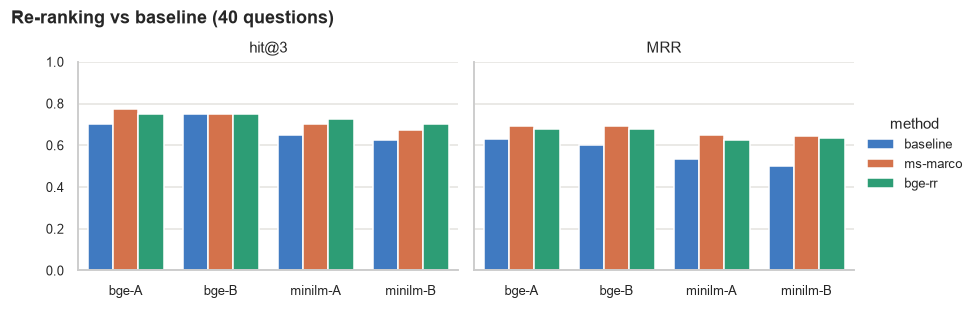

In [24]:
ml = summary.reset_index().melt(id_vars="setup", value_vars=[c for c in summary if c.startswith(("hit@3", "MRR"))])
ml[["metric", "method"]] = ml.variable.str.split(" ", n=1, expand=True)
g = sns.catplot(ml, kind="bar", x="setup", y="value", hue="method", col="metric", palette=[C["blue"], C["orange"], C["aqua"]],
                height=2.8, aspect=1.4, edgecolor="white")
g.set(ylim=(0, 1)).set_titles("{col_name}").set_axis_labels("", "")
g.figure.suptitle("Re-ranking vs baseline (40 questions)", x=0.01, ha="left", fontweight="bold", y=1.05); plt.show()

In [25]:
# per tier, all setups pooled
runs.groupby("tier").apply(summarise)[["hit@3 baseline", "hit@3 ms-marco", "hit@3 bge-rr", "fixed", "broken"]].round(2)

,hit@3 baseline,hit@3 ms-marco,hit@3 bge-rr,fixed,broken
tier,,,,,
1,1.00,1.00,1.00,0.0,0.0
2,0.78,0.80,0.80,1.0,0.0
3,0.50,0.55,0.62,8.0,6.0
4,0.45,0.55,0.50,7.0,3.0


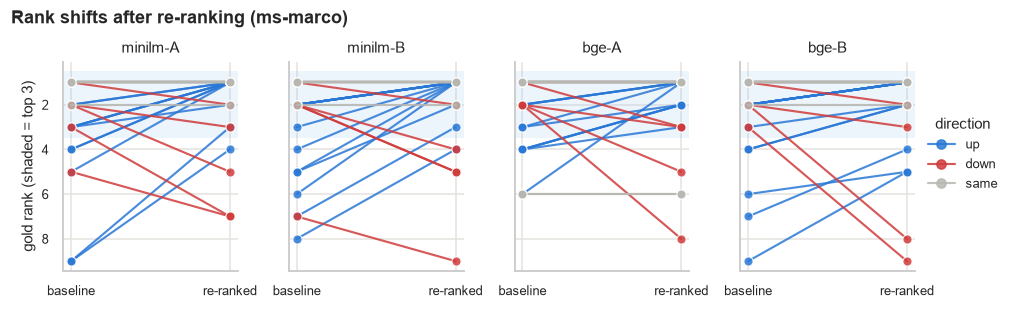

In [26]:
rs = runs.dropna(subset=["gold_base"]).copy()
rs["direction"] = np.select([rs.gold_rr < rs.gold_base, rs.gold_rr > rs.gold_base], ["up", "down"], "same")
sl = rs.melt(id_vars=["qid", "setup", "direction"], value_vars=["gold_base", "gold_rr"], var_name="stage", value_name="rank")
sl["stage"] = sl.stage.map({"gold_base": "baseline", "gold_rr": "re-ranked"})
g = sns.relplot(sl, kind="line", x="stage", y="rank", units="qid", estimator=None, hue="direction", col="setup", marker="o",
                hue_order=["up", "down", "same"], palette=[C["blue"], C["bad"], C["gray"]], height=2.8, aspect=0.75, lw=1.4, alpha=0.85)
for ax in g.axes.flat:
    ax.axhspan(0.5, 3.5, color=C["z2"], alpha=0.15, lw=0)
g.axes.flat[0].invert_yaxis()                      # shared y: rank 1 at the top
g.set_titles("{col_name}").set_axis_labels("", "gold rank (shaded = top 3)")
g.figure.suptitle("Rank shifts after re-ranking (ms-marco)", x=0.01, ha="left", fontweight="bold", y=1.05); plt.show()

In [27]:
moved = runs[(runs.gold_base != runs.gold_rr) & runs.gold_base.notna()]
moved.assign(question=moved.qid.map(QUESTION).str[:70])[["setup", "qid", "tier", "question", "gold_base", "gold_rr", "gold_rr_bge"]] \
     .sort_values(["setup", "gold_rr"]).reset_index(drop=True)

,setup,qid,tier,question,gold_base,gold_rr,gold_rr_bge
0,bge-A,q08,1,How many fast short-pitched deliveries can a bowler bowl in an over?,2.0,1.0,1.0
1,bge-A,q24,3,Rain holds up the start just after the toss. Can the team batting firs,2.0,1.0,1.0
2,bge-A,q34,4,"In the one-over eliminator, if a team already used up both its reviews",2.0,1.0,1.0
3,bge-A,q35,4,"In a 7-overs-a-side rain game, what's the most a single bowler can sen",6.0,1.0,5.0
4,bge-A,q40,4,"If a semi-final gets rained off halfway through, do they replay it fro",3.0,1.0,1.0
...,...,...,...,...,...,...,...
62,minilm-B,q26,3,"If the batters turn back halfway through a run, do they get penalised",8.0,4.0,3.0
63,minilm-B,q36,4,What time does the final start if it goes to the reserve day?,2.0,4.0,4.0
64,minilm-B,q22,3,The umpire calls a wide down the leg side and the keeper whips the bai,2.0,5.0,6.0
65,minilm-B,q33,4,"If the tie-breaker over is also level, can the guy who bowled it bowl",2.0,5.0,5.0


In [28]:
# free the GPUs for the LLM server: retrieval models wait on CPU (section 6 moves the small ones back)
def park(models, device):
    for m in models:
        m.to(device)
    torch.cuda.empty_cache()

park([*encoders.values(), *RERANKERS.values()], "cpu")
print("GPU memory held by this notebook:", [f"{torch.cuda.memory_reserved(d) / 2**30:.2f} GiB" for d in range(NGPU)])

GPU memory held by this notebook: ['0.02 GiB', '0.02 GiB', '0.02 GiB', '0.00 GiB']


## 4. LLM answers
`Qwen/Qwen3-32B-AWQ` (Qwen's official 4-bit release), served by vLLM with tensor parallelism over all 4 GPUs (`scripts/serve_llm.sh`), thinking off, temperature 0.
Three answers per question: **No RAG** (question only), **Answer 1** (baseline top 3), **Answer 2** (re-ranked top 3, same prompt).
Answers are cached by (model, prompt) in `outputs/llm_cache.json`. The server is only started when an answer isn't cached, so a re-run doesn't need it, and retrieval (sections 2–3) never shares the GPUs with it.

In [29]:
import requests, subprocess
LLM_HOST, LLM_NAME = "http://localhost:8000", "qwen3-32b"
LLM_URL = f"{LLM_HOST}/v1"

def server_up():
    try:
        return requests.get(f"{LLM_HOST}/health", timeout=2).ok
    except requests.RequestException:
        return False

def ensure_server(timeout=900):
    """Start the vLLM server (scripts/serve_llm.sh) only when it's needed and not already running."""
    if server_up():
        return
    print("starting vLLM server…")
    subprocess.Popen(["bash", str(ROOT / "scripts" / "serve_llm.sh")], start_new_session=True)
    t0 = time.time()
    while not server_up():
        if time.time() - t0 > timeout:
            raise RuntimeError("vLLM server did not start, see outputs/vllm.log")
        time.sleep(5)
    print(f"server up in {time.time() - t0:.0f}s")
CACHE = OUT / "llm_cache.json"
cache = json.loads(CACHE.read_text()) if CACHE.exists() else {}
cache_key = lambda msgs, n: hashlib.sha256(json.dumps([LLM_NAME, msgs, n]).encode()).hexdigest()[:20]

def chat(msgs, max_tokens):
    r = requests.post(f"{LLM_URL}/chat/completions", timeout=600, json={
        "model": LLM_NAME, "messages": msgs, "temperature": 0, "max_tokens": max_tokens,
        "chat_template_kwargs": {"enable_thinking": False}})
    r.raise_for_status()
    return r.json()["choices"][0]["message"]["content"].strip()

def generate(conversations, max_tokens=200, workers=64):
    """Cached; uncached prompts go to vLLM concurrently (it batches them on the GPUs). The server is only started if needed."""
    todo = {cache_key(c, max_tokens): c for c in conversations if cache_key(c, max_tokens) not in cache}
    if todo:
        ensure_server()
        t0 = time.perf_counter()
        try:
            with ThreadPoolExecutor(workers) as ex:
                futures = {ex.submit(chat, c, max_tokens): k for k, c in todo.items()}
                for n, f in enumerate(as_completed(futures), 1):
                    cache[futures[f]] = f.result()
                    if n % 50 == 0:
                        CACHE.write_text(json.dumps(cache, indent=0))
        finally:                                   # keep finished answers even if a request fails
            CACHE.write_text(json.dumps(cache, indent=0))
        print(f"generated {len(todo)} in {time.perf_counter() - t0:.0f}s")
    return [cache[cache_key(c, max_tokens)] for c in conversations]

### 4.1 Prompts
The RAG prompt is identical for Answer 1 and Answer 2; only the 3 chunks differ. Each chunk is shown with its section path in both versions, so A vs B differs only in *which* chunks were retrieved.

In [30]:
NO_RAG_SYSTEM = ("You answer questions about the ICC Men's T20 World Cup 2026 Playing Conditions from your own knowledge. "
                 "If you don't know, say so. Answer in 1-3 sentences.")
RAG_SYSTEM = ("You answer questions about the ICC Men's T20 World Cup 2026 Playing Conditions. "
              "Use only the context. If the context doesn't contain the answer, say \"Not in the context.\" "
              "Answer in 1-3 sentences.")

def no_rag_messages(question):
    return [{"role": "system", "content": NO_RAG_SYSTEM}, {"role": "user", "content": question}]

def rag_messages(question, ids):
    ctx = "\n\n".join(f"[{k}] {by_id.at[i, 'section_path']}\n{by_id.at[i, 'text']}" for k, i in enumerate(ids, 1))
    return [{"role": "system", "content": RAG_SYSTEM}, {"role": "user", "content": f"Context:\n{ctx}\n\nQuestion: {question}"}]

# exact input for one Answer 2 call (q23, MiniLM-A); chunk text shortened here for display only
r = runs[(runs.qid == "q23") & (runs.setup == "minilm-A")].iloc[0]
for msg in rag_messages(QUESTION["q23"], r.rr_top10[:3]):
    print(f"--- {msg['role']}\n" + re.sub(r"(\[\d\] [^\n]+\n)(.{150}).*", r"\1\2…", msg["content"]))

--- system
You answer questions about the ICC Men's T20 World Cup 2026 Playing Conditions. Use only the context. If the context doesn't contain the answer, say "Not in the context." Answer in 1-3 sentences.
--- user
Context:
[1] Appendix A: Definitions > 8 Substitutes and Concussion Replacements
8.1 A Substitute is a player who takes the place of a fielder on the field of play, but does not replace the player for whom he substitutes on that si…

[2] 1 The Players
1.2.7.3 The ICC Match Referee should ordinarily approve a Concussion Replacement Request if the replacement is a like-for-like player whose inclusion …

[3] 1 The Players
1.2.7.1.3.4 identify the requested Concussion Replacement from the list of nominated concussion replacements submitted for the match, who shall be a l…

Question: Can a concussed player be replaced by someone who isn't on the nominated list?


### 4.2 Generate

In [31]:
plan = [(q.qid, "none", "no_rag", no_rag_messages(q.question), "") for q in qs.itertuples()]
for r in runs.itertuples():
    for mode, top in [("baseline", r.base_top10[:3]), ("reranked", r.rr_top10[:3])]:
        plan.append((r.qid, r.setup, mode, rag_messages(QUESTION[r.qid], top), ",".join(top)))

texts = generate([p[3] for p in plan])
answers = pd.DataFrame([{"qid": qid, "setup": s, "mode": mode, "context": ctx, "answer": a}
                        for (qid, s, mode, _, ctx), a in zip(plan, texts)]).merge(qs[["qid", "tier"]], on="qid")
print(len(answers), "answers")

360 answers


In [32]:
# example: the three answers for q23 (MiniLM-A)
ex = answers[(answers.qid == "q23") & answers.setup.isin(["none", "minilm-A"])]
print("Q:", QUESTION["q23"], "\nExpected:", qs.set_index("qid").at["q23", "expected_answer"], "\n")
for r in ex.itertuples():
    print(f"[{r.mode}] context {r.context or '-'}\n{r.answer}\n")

Q: Can a concussed player be replaced by someone who isn't on the nominated list? 
Expected: Normally no, but in exceptional circumstances the match referee will consider it. 

[no_rag] context -
No, a concussed player cannot be replaced by someone who is not on the nominated 15-player squad list. Replacement of a player due to concussion must be done by another player from the same team's reserve or replacement list, as per ICC regulations.

[baseline] context c003,c343,c438
No, a concussed player can only be replaced by a player who is on the nominated list. According to the Playing Conditions, a Concussion Replacement must be a pre-match designated player and an official squad member.

[reranked] context c343,c009,c008
Yes, a concussed player can be replaced by someone who isn't on the nominated list, but only under exceptional circumstances. In such cases, the ICC Match Referee will consider the request and apply specific provisions to ensure fairness.



### 4.3 Grading
The same LLM grades every answer against the expected answer with a fixed rubric:
**correct** (key facts and conditions right) · **partial** (right core, a required condition missing) · **wrong** (contradicts the rule) · **abstain** (gives no answer).
A wrong answer given confidently counts as a **hallucination**. Grades were spot-checked independently (see section 5).

In [33]:
JUDGE_SYSTEM = ("You grade answers about cricket rules against a reference answer written from the rulebook. "
                "Judge only meaning, not wording or length. Labels: "
                "correct = states the reference's key fact and any condition or exception it includes; "
                "partial = the core is right but a required condition or exception is missing; "
                "wrong = contradicts the reference or gives a different fact; "
                "abstain = gives no answer (e.g. says it doesn't know or the context doesn't say). "
                "A hedged answer that still commits to an answer is graded on that answer. "
                'Reply with JSON only: {"label": "...", "reason": "<10 words>"}')

def judge_messages(qid, answer):
    q = qs.set_index("qid").loc[qid]
    return [{"role": "system", "content": JUDGE_SYSTEM},
            {"role": "user", "content": f"Question: {q.question}\nReference answer: {q.expected_answer}\nCandidate answer: {answer}"}]

def parse(v):
    m = re.search(r'"label"\s*:\s*"(\w+)"', v)
    return m.group(1).lower() if m and m.group(1).lower() in {"correct", "partial", "wrong", "abstain"} else "wrong"

raw = generate([judge_messages(r.qid, r.answer) for r in answers.itertuples()], max_tokens=60)
answers["llm_label"], answers["judge"] = [parse(v) for v in raw], raw
answers["answer_sha"] = answers.answer.map(lambda a: hashlib.sha1(a.encode()).hexdigest()[:12])
ex = answers[(answers.qid == "q23") & (answers.setup == "minilm-A") & (answers["mode"] == "reranked")].iloc[0]
print("example grader input:\n" + judge_messages(ex.qid, ex.answer)[1]["content"], "\n\ngrader output:", ex.judge)

example grader input:
Question: Can a concussed player be replaced by someone who isn't on the nominated list?
Reference answer: Normally no, but in exceptional circumstances the match referee will consider it.
Candidate answer: Yes, a concussed player can be replaced by someone who isn't on the nominated list, but only under exceptional circumstances. In such cases, the ICC Match Referee will consider the request and apply specific provisions to ensure fairness. 

grader output: {"label": "correct", "reason": "States the key fact and includes the condition/exception"}


### 4.4 Grader check
Every unique answer (175) was also graded **blind** by a second model (Claude Haiku) with the same rubric, saved in `eval/haiku_grades.csv`.
Where they disagreed by a full step (correct vs wrong/abstain), the answer was read by hand; the 5 confirmed grader errors are corrected via `eval/grade_overrides.csv`.

In [34]:
haiku = pd.read_csv(ROOT / "eval" / "haiku_grades.csv")
chk = answers.drop_duplicates(["qid", "answer_sha"]).merge(haiku, on=["qid", "answer_sha"], how="inner", suffixes=("", "_haiku"))
step = {"correct": 1, "partial": 0.5, "abstain": 0, "wrong": 0}
print(f"{len(chk)} answers | exact agreement {(chk.llm_label == chk.label).mean():.0%} | "
      f"within one step {((chk.llm_label.map(step) - chk.label.map(step)).abs() <= 0.5).mean():.0%}")
pd.crosstab(chk.llm_label, chk.label, rownames=["Qwen3-32B"], colnames=["Haiku (blind)"])

175 answers | exact agreement 79% | within one step 97%


Haiku (blind),abstain,correct,partial,wrong
Qwen3-32B,,,,
abstain,10,0,0,0
correct,1,63,17,3
partial,0,5,23,4
wrong,4,1,2,42


In [35]:
overrides = pd.read_csv(ROOT / "eval" / "grade_overrides.csv")
answers = answers.merge(overrides[["qid", "answer_sha", "label"]], on=["qid", "answer_sha"], how="left")
answers["label"] = answers.label.fillna(answers.llm_label)
answers["score"] = answers.label.map({"correct": 1, "partial": 0.5}).fillna(0)
answers["hallucination"] = answers.label.eq("wrong")
answers.to_csv(OUT / "answers.csv", index=False)
print(f"{(answers.label != answers.llm_label).sum()} answer rows corrected")
overrides[["qid", "llm_label", "label", "reason"]]

14 answer rows corrected


,qid,llm_label,label,reason
0,q31,correct,wrong,Says all 15 can bat; the rule allows at most 11
1,q24,correct,wrong,Says the roller is not allowed; the rule allows up to 7 minutes
2,q25,correct,abstain,Says 'Not in the context' (no answer given)
3,q12,wrong,correct,Not out unless the ball would have hit the wicket: matches the rule
4,q24,correct,wrong,Says the roller is not allowed; the rule allows up to 7 minutes


In [36]:
LABELS = ["correct", "partial", "abstain", "wrong"]
by_mode = answers.groupby(["mode", "setup"]).label.value_counts(normalize=True).unstack(fill_value=0).reindex(columns=LABELS, fill_value=0)
by_mode["score"] = answers.groupby(["mode", "setup"]).score.mean()
by_mode.round(2)

label              correct  partial  abstain  wrong  score
mode     setup                                            
baseline bge-A        0.60     0.10     0.18   0.12   0.65
         bge-B        0.62     0.15     0.10   0.12   0.70
         minilm-A     0.57     0.20     0.10   0.12   0.68
         minilm-B     0.50     0.18     0.18   0.15   0.59
no_rag   none         0.28     0.15     0.02   0.55   0.35
reranked bge-A        0.68     0.10     0.12   0.10   0.72
         bge-B        0.68     0.10     0.12   0.10   0.72
         minilm-A     0.60     0.10     0.12   0.18   0.65
         minilm-B     0.60     0.08     0.12   0.20   0.64

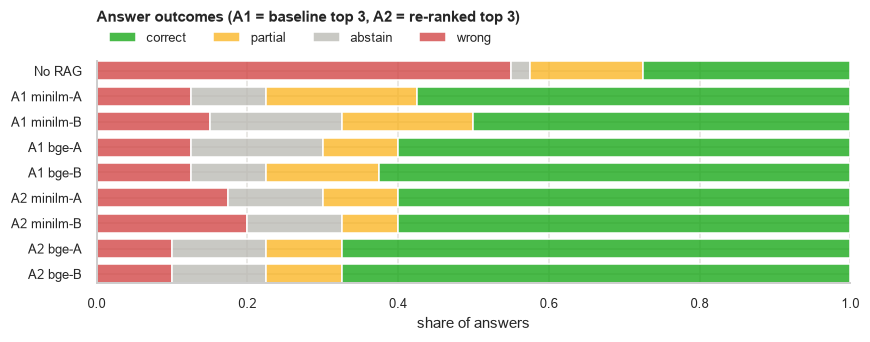

In [37]:
ol = answers.assign(run=np.where(answers["mode"] == "no_rag", "No RAG",
                                  answers["mode"].map({"baseline": "A1", "reranked": "A2"}).fillna("") + " " + answers.setup))
run_order = ["No RAG"] + [f"{a} {s}" for a in ["A1", "A2"] for s in ["minilm-A", "minilm-B", "bge-A", "bge-B"]]
ol["run"] = pd.Categorical(ol.run, categories=run_order)
fig, ax = plt.subplots(figsize=(8, 3.2))
sns.histplot(ol, y="run", hue="label", multiple="fill", discrete=True, shrink=0.75, hue_order=LABELS,
             palette=[C["good"], C["warn"], C["gray"], C["bad"]], edgecolor="white", ax=ax)
ax.set_xlabel("share of answers"); ax.set_ylabel("")
sns.move_legend(ax, "lower left", bbox_to_anchor=(0, 1.02), ncol=4, title=None, frameon=False)
ax.set_title("Answer outcomes (A1 = baseline top 3, A2 = re-ranked top 3)", loc="left", fontweight="bold", pad=26)
plt.tight_layout(); plt.show()

In [38]:
# score by tier: No RAG vs Answer 1 vs Answer 2 (RAG modes averaged over the 4 setups)
answers.pivot_table(index="tier", columns="mode", values="score", aggfunc="mean")[["no_rag", "baseline", "reranked"]].round(2)

mode,no_rag,baseline,reranked
tier,,,
1,0.3,1.00,1.00
2,0.5,0.71,0.75
3,0.5,0.57,0.59
4,0.1,0.32,0.40


## 5. Failure analysis
*(after the results are reviewed)*

## 6. Latency
Per-query timings (MiniLM-A, mean of 40 queries after 5 warm-ups); `torch.cuda.synchronize()` before and after each GPU call.
The last rows answer the scaling question: a cross-encoder over **all** chunks vs the bi-encoder search, plus batched throughput.

In [ ]:
def sync():
    for d in range(torch.cuda.device_count()):
        torch.cuda.synchronize(d)

def bench(fn, inputs, warmup=5, gpu=False):
    for x in inputs[:warmup]:
        fn(x)
    times = []
    for x in inputs:
        if gpu: sync()
        t0 = time.perf_counter(); fn(x)
        if gpu: sync()
        times.append((time.perf_counter() - t0) * 1000)
    return round(float(np.mean(times)), 2), round(float(np.std(times)), 2)

park([encoders["minilm"], RERANKERS["ms-marco"]], DEVICE)     # back on GPU 0 for the GPU timings
questions = qs.question.tolist()
index = indexes[("minilm", "A")]
texts = chunks.text.tolist()
lat = []
for dev in ([DEVICE] if NGPU else []) + ["cpu"]:
    on_gpu = dev != "cpu"
    enc = encoders["minilm"] if on_gpu else SentenceTransformer(BI_ENCODERS["minilm"][0], device="cpu")
    ce = RERANKERS["ms-marco"] if on_gpu else CrossEncoder("cross-encoder/ms-marco-MiniLM-L6-v2", device="cpu")
    embed = lambda q: enc.encode([q], normalize_embeddings=True, convert_to_numpy=True)
    qemb = {q: embed(q) for q in questions}
    top10 = {q: index.search(qemb[q], 10)[1][0] for q in questions}
    def pipeline2(q):
        _, idx = index.search(embed(q), 10)
        return ce.predict([(q, texts[i]) for i in idx[0]], show_progress_bar=False)
    stages = {
        "query embedding": lambda q: embed(q),
        "vector search (top 10)": lambda q: index.search(qemb[q], 10),
        "re-rank 10 pairs": lambda q: ce.predict([(q, texts[i]) for i in top10[q]], show_progress_bar=False),
        "Pipeline 1 retrieval": lambda q: index.search(embed(q), 10),
        "Pipeline 2 retrieval": pipeline2,
        f"cross-encoder on all {len(chunks)} chunks": lambda q: ce.predict([(q, t) for t in texts], batch_size=128, show_progress_bar=False),
    }
    for name, fn in stages.items():
        full = name.startswith("cross-encoder on all")
        mean, std = bench(fn, questions[:10] if full else questions, warmup=2 if full else 5, gpu=on_gpu)
        lat.append({"device": "GPU" if on_gpu else "CPU", "stage": name, "mean ms": mean, "std ms": std})
    # batched throughput: all 40 questions through Pipeline 2 at once
    t0 = time.perf_counter(); _, idx = index.search(enc.encode(questions, normalize_embeddings=True), 10)
    ce.predict([(q, texts[i]) for q, row in zip(questions, idx) for i in row], batch_size=64, show_progress_bar=False)
    if on_gpu: sync()
    lat.append({"device": "GPU" if on_gpu else "CPU", "stage": "Pipeline 2, 40 queries batched (per query)",
                "mean ms": round((time.perf_counter() - t0) * 1000 / len(questions), 2), "std ms": np.nan})

In [ ]:
# LLM answer time: one uncached request to the vLLM server (Answer 1 prompt), 10 questions
_, idx = index.search(encoders["minilm"].encode(questions[:10], normalize_embeddings=True), 3)
llm_inputs = [rag_messages(q, CHUNK_IDS[row]) for q, row in zip(questions[:10], idx)]
ensure_server()
mean, std = bench(lambda c: chat(c, 200), llm_inputs, warmup=2)
lat.append({"device": "GPU x4 (vLLM)", "stage": "LLM answer", "mean ms": mean, "std ms": std})
latency = pd.DataFrame(lat)
latency.to_csv(OUT / "latency.csv", index=False)
latency

In [ ]:
lt = latency[latency.stage != "LLM answer"]
fig, ax = plt.subplots(figsize=(8, 3.2))
sns.barplot(lt, y="stage", x="mean ms", hue="device", hue_order=["GPU", "CPU"], palette=[C["blue"], C["orange"]], ax=ax)
ax.set_xscale("log"); ax.set_xlabel("ms per query (log scale)"); ax.set_ylabel("")
sns.move_legend(ax, "lower right", title=None)
ax.set_title("Retrieval latency per query", loc="left", fontweight="bold"); plt.tight_layout(); plt.show()